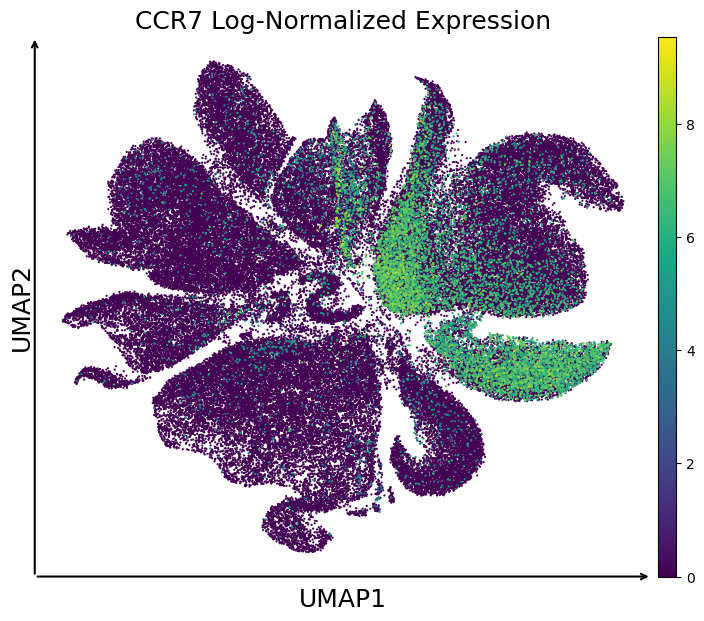

In [24]:
import scanpy as sc
import matplotlib.pyplot as plt
from matplotlib.pyplot import rc_context

adata_sc = sc.read("../h5ad/adata_sc.h5ad")

sc.pp.normalize_total(adata_sc, target_sum=1e6)
sc.pp.log1p(adata_sc)

color_map = {
        'B cell': '#ff7f0e',          
        'Endothelial cell': '#1f77b4',
        'Epithelial cell': '#7f7f7f', 
        'Fibroblast': '#9467bd',  
        'Muscle cell': '#8c564b',     
        'Myeloid cell': '#d62728',    
        'Plasma cell': '#bcbd22',     
        'T cell': '#17becf'           
    }
color_map["Mast cell"] =  "#e377c2"   
color_map["Schwann cell"] = '#2ca02c'

# Use rc_context to control figure size
with rc_context({"figure.figsize": (7, 6)}):
    sc.pl.umap(
        adata_sc, 
        color=['CCR7'], 
        palette=color_map, 
        size=10, 
        alpha=1.0, 
        frameon=False,  
        show=False,
        title="CCR7 Log-Normalized Expression",
    )

# 2. Get the current axes object
ax = plt.gca()
ax.set_title("CCR7 Log-Normalized Expression", fontsize=18)

# 3. Hide the top and right spines
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# 4. Get the axis limits
x_min, x_max = ax.get_xlim()
y_min, y_max = ax.get_ylim()

# 5. Add axis arrows
# X-axis arrow
ax.annotate(
    '', xy=(x_max, y_min), xytext=(x_min, y_min),
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)
# Y-axis arrow
ax.annotate(
    '', xy=(x_min, y_max), xytext=(x_min, y_min),
    arrowprops=dict(arrowstyle='->', lw=1.5, color='black')
)

# 6. Add centered axis labels
# Calculate offsets so labels do not sit too close to the arrows
offset_x = (x_max - x_min) * 0.02
offset_y = (y_max - y_min) * 0.02

# UMAP1 label: centered below the X axis
ax.text(
    x_min + (x_max - x_min) / 2,  # X-axis midpoint
    y_min - offset_x,             # Slightly below the Y-axis minimum
    'UMAP1', 
    ha='center', va='top',        # Horizontally centered, vertically top-aligned
    fontsize=18
)

# UMAP2 label: centered on the left side of the Y axis, rotated 90 degrees
ax.text(
    x_min - offset_y,             # Slightly to the left of the X-axis minimum
    y_min + (y_max - y_min) / 2,  # Y-axis midpoint
    'UMAP2', 
    ha='center', va='center',     # Centered both horizontally and vertically
    fontsize=18, 
    rotation=90                   # Rotate vertical label by 90 degrees
)
plt.tight_layout(pad=0)
plt.show()